# ORCA end-to-end walkthrough

**Generative conformal prediction with Optimized Ranking and Coverage Allocation.**

This notebook runs the whole pipeline on one synthetic dataset and shows what each
stage contributes:

| stage | module | what happens |
|---|---|---|
| 0 | `orca.data` | generate data, split into train / exploration / calibration / test |
| 1 | `orca.models` | fit a generative model of $p(Y \mid X)$ |
| 2 | `orca.sampling` | sample, rank by local density, build residual matrices |
| 3 | `orca.optimize` | solve the coverage-allocation MILP for per-rank radii |
| 4 | `orca.conformal` | split-conformal calibration |
| 5 | `orca.plotting` | figures |

**The idea in one paragraph.** Classical conformal prediction collapses a
predictive distribution to one number and pays for one radius. ORCA keeps the
whole generated cloud, sorts each point's samples from *densest* to *most
isolated*, and then buys a **separate radius per rank**. Choosing those radii is
an optimization problem — minimise the total volume subject to covering
$1-\alpha$ of an exploration set — which we solve exactly as a mixed-integer
linear program. A final split-conformal step rescales the whole radius vector,
which is what makes coverage exact in finite samples *regardless* of how well the
optimizer did.

In [1]:
import sys
from pathlib import Path

# Run from the repo root or from notebooks/ -- both work.
ROOT = Path.cwd() if (Path.cwd() / "orca").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from orca import conformal, data, metrics, models, optimize, plotting, sampling

plotting.apply_style()

ALPHA = 0.10        # target miscoverage -> 90% nominal coverage
K = 20              # generated samples per input
SEED = 0
rng = np.random.default_rng(SEED)

print("ORCA pipeline | alpha =", ALPHA, "| K =", K)

ORCA pipeline | alpha = 0.1 | K = 20


## Stage 0 — data

We use `s-shape`: a 1-D input against a 1-D response whose conditional
distribution $Y \mid X$ is **multimodal** — for most values of $X$ there are two
or three plausible bands of $Y$. That is exactly the regime where a single
interval is wasteful, because it has to span the empty space between modes.

X (4000, 1)  Y (4000, 1)


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


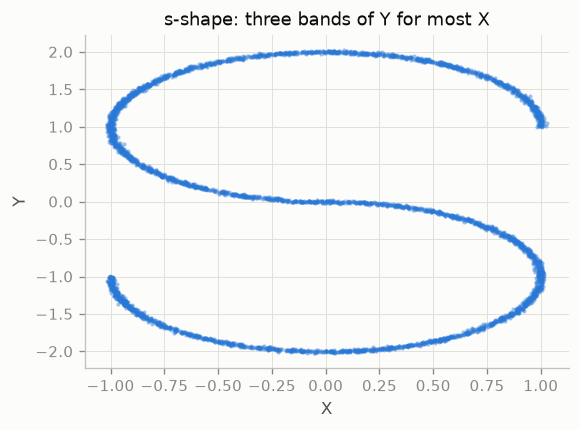

In [2]:
X, Y = data.generate_synthetic("s-shape", n=4000, noise=0.01, seed=SEED)
print("X", X.shape, " Y", Y.shape)

fig, ax = plt.subplots(figsize=(5.2, 3.6))
plotting.plot_dataset(X, Y, ax=ax, title="s-shape: three bands of Y for most X")
plt.show()

The split. `n_train` points train the generative model; everything else goes
into a **pool** that we re-split into calibration and test. Doing it this way
means we train once and can repeat the conformal step many times cheaply.

In [3]:
n_train, n_calib, n_test = 2000, 1000, 1000
idx_train, idx_pool = data.train_pool_split(len(X), n_train, seed=SEED)
idx_calib, idx_test = data.sample_cal_test_from_pool(idx_pool, n_calib, n_test, seed=SEED + 1)

print(f"train {len(idx_train)} | pool {len(idx_pool)} -> calib {len(idx_calib)} + test {len(idx_test)}")
assert set(idx_train).isdisjoint(idx_pool) and set(idx_calib).isdisjoint(idx_test)

train 2000 | pool 2000 -> calib 1000 + test 1000


## Stage 1 — the generative model

ORCA needs only one thing from a model: the ability to **draw samples** from
$p(Y \mid X)$. Here we fit a quantile network — an MLP trained with the pinball
loss across a grid of quantile levels — and sample by inverting the fitted
conditional quantile function.

Anything with a `.sample(X, n_sample, rng)` method slots in unchanged: a mixture
density network, a normalising flow, a diffusion model, a conditional VAE.

In [4]:
model = models.QuantileNet(
    num_features=X.shape[1],
    num_hidden=256,
    dropout=0.1,
    learning_rate=5e-3,
    num_epochs=400,
    batch_size=512,
    random_state=SEED,
    verbose=True,
    log_every=100,
)
model.fit(X[idx_train], Y[idx_train].ravel())
print("final pinball loss:", round(model.loss_history[-1], 5))

  epoch  100/400 | pinball loss 0.37775


  epoch  200/400 | pinball loss 0.37540


  epoch  300/400 | pinball loss 0.37519


  epoch  400/400 | pinball loss 0.37467
final pinball loss: 0.37467


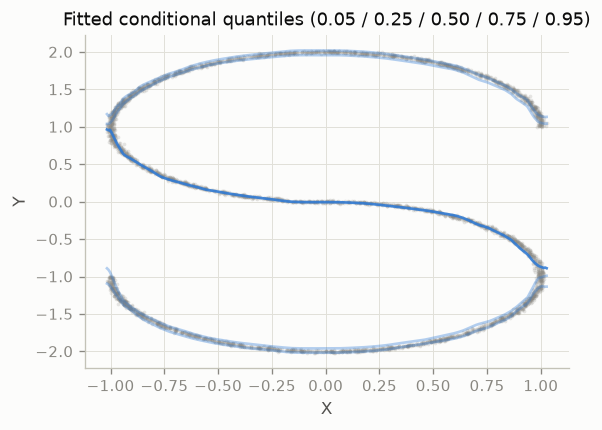

In [5]:
# The fitted conditional quantile curves, which is what we sample from.
grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
q_pred = model.predict(grid)
levels = model.get_quantiles()

fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.scatter(X[:, 0], Y[:, 0], s=5, alpha=0.20, linewidths=0, color=plotting.PALETTE["muted"])
for lv in (0.05, 0.25, 0.50, 0.75, 0.95):
    j = int(np.argmin(np.abs(levels - lv)))
    ax.plot(grid[:, 0], q_pred[:, j], linewidth=1.6,
            color=plotting.PALETTE["series_1"], alpha=0.35 + 0.5 * (lv == 0.50))
ax.set_xlabel("X"); ax.set_ylabel("Y")
ax.set_title("Fitted conditional quantiles (0.05 / 0.25 / 0.50 / 0.75 / 0.95)")
for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.show()

Note what the quantile curves *cannot* do: they are monotone in the level, so
they trace bands, and any single interval between two of them swallows the gaps
between the modes. The samples are what carry the multimodality — which is why
ORCA works with the samples rather than the curves.

## Stage 2 — sample, rank, and build the residual matrix

For every pool point we draw $K$ samples and sort them by a **local density
proxy**: each sample's mean distance to its nearest neighbours within the same
cloud. Rank 1 sits in the densest part of the cloud, rank $K$ is the most
isolated.

Then we record the residual matrix $E[i, r] = \lVert Y_i - \hat Y_{i,(r)}\rVert$.
Everything downstream is a function of $E$ alone.

In [6]:
mats = sampling.build_sample_matrices(
    model, X[idx_pool], Y[idx_pool], n_sample=K, rng=rng, norm="l2",
)

pool_pos = {int(g): i for i, g in enumerate(idx_pool)}
cal_pos = np.array([pool_pos[int(i)] for i in idx_calib])
test_pos = np.array([pool_pos[int(i)] for i in idx_test])

E_cal,  E_test  = mats["E"][cal_pos],          mats["E"][test_pos]           # ranked -> ORCA
E_cal_raw, E_test_raw = mats["E_unranked"][cal_pos], mats["E_unranked"][test_pos]  # raw -> PCP
Yhat_test_ranked = mats["Y_hat_ranked"][test_pos]
Yhat_test_raw    = mats["Y_hat"][test_pos]

print("residual matrix E:", E_cal.shape, "(n_calib x K)")
print("mean residual by rank:", np.round(E_cal.mean(axis=0), 3))

residual matrix E: (1000, 20) (n_calib x K)
mean residual by rank: [1.688 1.694 1.69  1.692 1.695 1.684 1.685 1.703 1.569 1.542 1.581 1.535
 1.542 1.636 1.684 1.16  1.147 1.159 1.168 1.158]


The mean residual is **not constant across ranks** — that is the whole
opening. Which direction it tilts is data-dependent (here the high ranks sit
*closer* to the truth on average, because the densest part of the generated cloud
is not where the response actually falls for this dataset); what matters is only
that the ranks are distinguishable. A single shared radius, as PCP uses, has to
be big enough for the worst rank. ORCA can spend differently on each one.

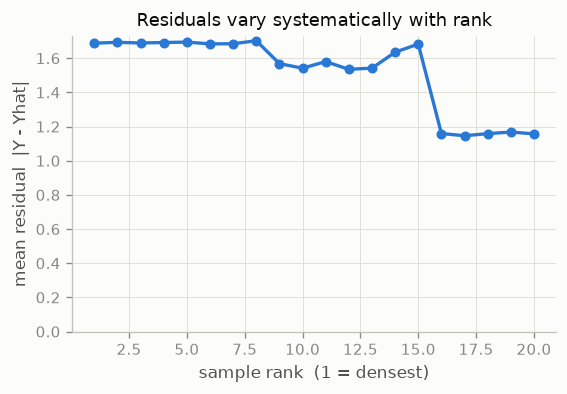

In [7]:
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(np.arange(1, K + 1), E_cal.mean(axis=0), marker="o", markersize=5,
        linewidth=2, color=plotting.PALETTE["series_1"])
ax.set_xlabel("sample rank  (1 = densest)")
ax.set_ylabel("mean residual  |Y - Yhat|")
ax.set_title("Residuals vary systematically with rank")
ax.set_ylim(bottom=0)
for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.show()

## Stage 3 — optimized coverage allocation

Split the calibration set in two. The **exploration half** feeds the optimizer;
the **calibration half** is held back for stage 4 and must never be seen by the
optimizer, or validity is lost.

We solve

$$\min_{t_1,\dots,t_K} \ \sum_r t_r^{\,d} \qquad \text{s.t.}\qquad
\frac{1}{n_1}\#\{i : \min_r (E_{i,r} - t_r) \le 0\} \ \ge\ 1-\alpha .$$

Because the constraint depends on $t$ only through the comparisons
$E_{i,r} \le t_r$, an optimal $t_r$ can always be taken from the finite set of
observed residuals in column $r$ — which turns this into a MILP over level
indices, solved here with CP-SAT.

In [8]:
expl_idx, cal_idx = conformal.split_exploration_calibration(len(idx_calib), seed=SEED + 2)
E1, E2 = E_cal[expl_idx], E_cal[cal_idx]
print(f"exploration {E1.shape} -> optimizer | calibration {E2.shape} -> conformal step")

results = {}
for name, solver, kw in [
    ("ORCA-MILP",   "milp",   dict(time_limit=60)),
    ("ORCA-LP",     "lp",     dict()),
    ("ORCA-Greedy", "greedy", dict(with_zero=True)),
]:
    res = optimize.SOLVERS[solver](E1, ALPHA, d=1, **kw)
    results[name] = res
    print(f"{name:<12} proxy objective {res['obj_value']:.4f} | "
          f"exploration coverage {res['coverage']:.3f} | {res['method']}")

exploration (500, 20) -> optimizer | calibration (500, 20) -> conformal step


ORCA-MILP    proxy objective 0.1978 | exploration coverage 0.902 | ORCA-MILP (CP-SAT)


ORCA-LP      proxy objective 0.2500 | exploration coverage 0.902 | ORCA-LP (relaxation + cutoff rounding)


ORCA-Greedy  proxy objective 0.2062 | exploration coverage 0.902 | ORCA-Greedy (rank-jump set cover)


All three meet the coverage quota on the exploration set; they differ in the
objective they reach and in how long they take. The MILP is exact (given enough
time); the LP relaxation and the greedy set-cover are the scalable
approximations.

In [9]:
thr = results["ORCA-MILP"]["thresholds"]
alloc = pd.DataFrame({"rank": np.arange(1, K + 1), "threshold": thr}).sort_values(
    "threshold", ascending=False)

print("Largest and smallest per-rank thresholds chosen by the MILP:")
print(alloc.head(4).to_string(index=False, float_format=lambda v: f"{v:.5f}"))
print(" ...")
print(alloc.tail(3).to_string(index=False, header=False, float_format=lambda v: f"{v:.5f}"))
print(f"\nspread (largest / smallest threshold): {thr.max() / max(thr.min(), 1e-12):,.0f}x")
print(f"ranks carrying 90% of the proxy budget: "
      f"{int((np.cumsum(np.sort(thr)[::-1]) < 0.9 * thr.sum()).sum()) + 1} of {K}")

Largest and smallest per-rank thresholds chosen by the MILP:
 rank  threshold
    2    0.05761
   18    0.04435
   11    0.03265
   10    0.03006
 ...
 5 0.00018
 3 0.00016
17 0.00010

spread (largest / smallest threshold): 577x
ranks carrying 90% of the proxy budget: 6 of 20


## Stage 4 — split-conformal calibration

Stage 3 chose a **direction** in radius space, not a scale. Now we rescale it on
the held-out calibration half:

$$S_i = \min_r \frac{E_{i,r}}{t_r},\qquad
  q = \text{Quantile}_{1-\alpha}(S),\qquad R = q\, t .$$

Since $t$ was fixed before $E_2$ was touched, the scores $S_i$ are exchangeable
with the test score, so coverage is at least $1-\alpha$ in finite samples **no
matter what the optimizer returned**. A timed-out or sloppy solve costs
efficiency, never validity.

In [10]:
calibrated = {}
for name, res in results.items():
    m = conformal.ORCA(alpha=ALPHA, dimension_y=1)
    m.thresholds = res["thresholds"]      # reuse the stage-3 solution
    m.calibrate(E2)
    calibrated[name] = m
    print(f"{name:<12} conformal scale q = {m.scale:.4f}")

pcp = conformal.PCP(alpha=ALPHA)
pcp.calibrate(E_cal_raw)                  # PCP gets the *full* calibration set
print(f"{'PCP':<12} single radius  = {pcp.radius:.4f}")

ORCA-MILP    conformal scale q = 1.2444
ORCA-LP      conformal scale q = 1.2590
ORCA-Greedy  conformal scale q = 1.5679
PCP          single radius  = 0.0259


> PCP is given the whole calibration set while ORCA spends half of it on
> exploration. That handicaps ORCA, deliberately — the comparison below is
> conservative in the baseline's favour.

## Stage 5 — evaluate and plot

Two numbers matter: **coverage** (must reach $1-\alpha$) and **size** (smaller is
better). Size is the length of the *union* of intervals, with overlaps merged —
summing ball widths would badly overstate it.

In [11]:
rows = []
for name, m in calibrated.items():
    covered = m.coverage(E_test)
    sizes = metrics.region_size(Yhat_test_ranked, m.radius, reference_data=Y, dimension_y=1)
    rows.append(dict(method=name, **metrics.summarize(covered, sizes)))

covered_pcp = pcp.coverage(E_test_raw)
sizes_pcp = metrics.region_size(Yhat_test_raw, pcp.radius, reference_data=Y, dimension_y=1)
rows.append(dict(method="PCP", **metrics.summarize(covered_pcp, sizes_pcp)))

summary = pd.DataFrame(rows).sort_values("size_mean").reset_index(drop=True)
summary

,method,coverage,size_mean,size_median,size_mean_covered
0,ORCA-MILP,0.916,0.430000,0.431070,0.427852
1,ORCA-LP,0.914,0.435851,0.415355,0.428563
2,ORCA-Greedy,0.931,0.468686,0.454088,0.463429
3,PCP,0.896,0.509681,0.481842,0.502471


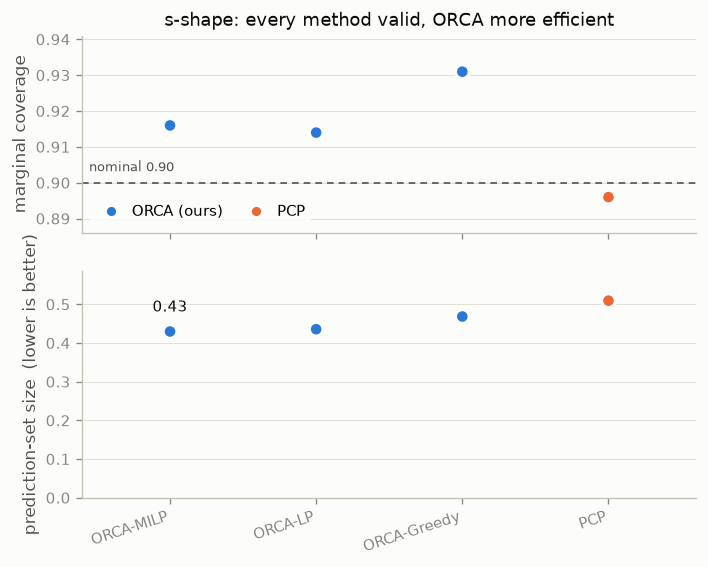

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(6.6, 5.0), sharex=True,
                         gridspec_kw={"height_ratios": [1.0, 1.15], "hspace": 0.18})
plotting.plot_coverage_efficiency(summary, alpha=ALPHA, axes=axes,
                                  title="s-shape: every method valid, ORCA more efficient")
plt.show()

### What the prediction sets look like

The payoff figure. Same data, same nominal coverage — the difference is entirely
in how the radius budget is spent.

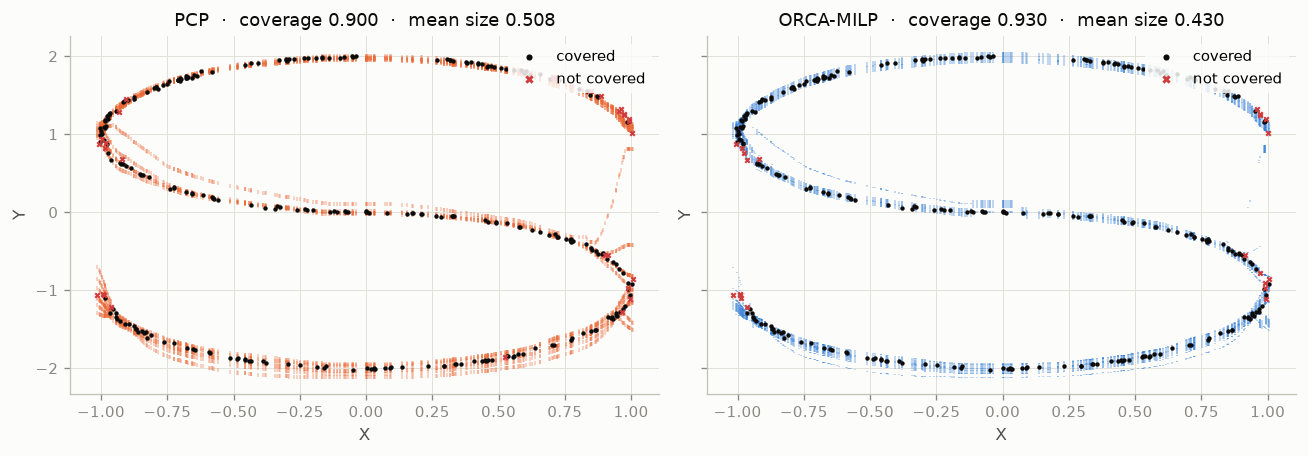

In [13]:
X_test_plot, Y_test_plot = X[idx_test], Y[idx_test]
best = summary.loc[summary.method.str.startswith("ORCA"), "method"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
plotting.plot_prediction_sets_1d(X_test_plot, Y_test_plot, Yhat_test_raw, pcp.radius,
                                 ax=axes[0], method_name="PCP")
plotting.plot_prediction_sets_1d(X_test_plot, Y_test_plot, Yhat_test_ranked,
                                 calibrated[best].radius, ax=axes[1], method_name=best)
plt.tight_layout()
plt.show()

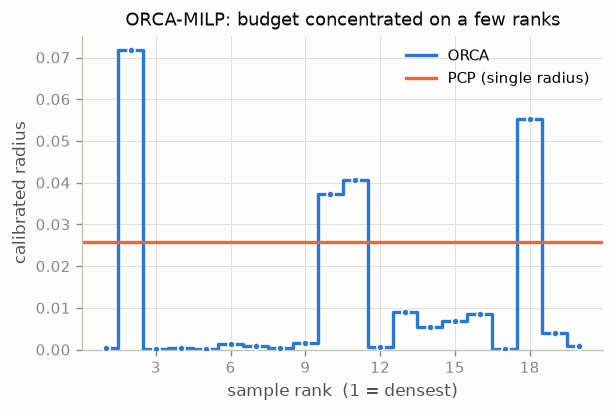

In [14]:
fig, ax = plt.subplots(figsize=(5.6, 3.4))
plotting.plot_radius_by_rank(calibrated[best].radius, pcp.radius, ax=ax,
                             title=f"{best}: budget concentrated on a few ranks")
plt.show()

Both methods scatter around 0.90 — that is the guarantee working. ORCA gets
there with a visibly smaller prediction set.

## Where to go next

- **Other datasets**: swap `"s-shape"` for any of the scalar-response sets in
  `orca.data.SYNTHETIC_DATASETS` — `circles`, `moon`, `roll`, `spiral`,
  `unbalance`, `balance`.
- **Your own generative model**: pass anything with `.sample(X, n_sample, rng)`
  to `sampling.build_sample_matrices`. This is also how you reach the
  multivariate case: `mix-gaussian` has a 2-D response, and the optimizer,
  calibration and volume estimator all handle `d > 1` (pass `dimension_y=2`),
  but `QuantileNet` fits a scalar response only, so you need to supply a
  multivariate sampler of your own.
- **Scaling**: the MILP is the bottleneck. Use `conformal.ORCA(solver="greedy")`
  for large $K$ or many repetitions; it runs in about a second.